# T09 — Running many sessions fast

*How do I run thousands of sessions fast?*

**What you will learn**

- how to compile a whole session into one program, with `jax.jit` of a `jax.lax.scan` over `step_env`;
- how to run a batch of sessions with `jax.vmap`, over seeds and over tapes;
- three rules: keep the batch shape fixed, turn on 64-bit mode for a batch, and keep compiled programs on disk;
- how to choose the device, a central processing unit (CPU) or a graphics processing unit (GPU), and how to
  measure which way is fastest on your machine.

This tutorial shows *how to use* these tools, as recipes to copy. It does not explain how JAX works
inside; the [JAX documentation](https://docs.jax.dev/en/latest/) does, and each recipe links the page it needs.

**What you need**

- Previous tutorials: [T05](T05_session.ipynb) (sessions) and [T06](T06_writing_an_agent.ipynb) (agents) help, but are not required.
- Run time: about 3 minutes on a CPU the first time, almost all of it compiling
  three programs; under a minute when the compiled programs are already on disk (section 6).
- Network: no.

## Setup

Imports, the device (CPU by default), the seeds, the figure style and the repository root.
Every data path is built from `ROOT`, never relative to this folder.

In [1]:
# Setup: device, repository root, seeds and the figure style. Run this cell first.
import os
import sys
from pathlib import Path

os.environ.setdefault("JAX_PLATFORMS", "cpu")  # CPU by default; export JAX_PLATFORMS=cuda before Jupyter for a GPU

# The repository root is the first folder above this notebook that holds pyproject.toml. It goes on
# sys.path because the data downloader (scripts/) is not part of the installed package.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
DATA_DIR = ROOT / "data" / "rawOMIE"  # every data path starts here (ignored by git), never under tutorials/

import jax
import matplotlib.pyplot as plt
import numpy as np

SEED = 0  # fixed seeds: a re-run gives the same market results
rng = np.random.default_rng(SEED)
key = jax.random.PRNGKey(SEED)

# Figure style, the same five lines in every tutorial: buy, sell, a third series, neutral.
BUY, SELL, THIRD, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9893"
plt.rcParams.update({"figure.figsize": (7, 3.2), "figure.dpi": 110, "savefig.dpi": 110, "font.size": 9.5,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "legend.frameon": False, "axes.titlesize": 10.5,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"})
print(f"JAX {jax.__version__}, backend: {jax.default_backend()}")

JAX 0.6.2, backend: cpu


One more setup line, before anything compiles: JAX keeps every compiled program in a folder on disk, so
the next run of this notebook loads it instead of compiling again. Section 6 explains it. The folder is
`.jax_cache/tutorials/` under the repository root; git ignores `.jax_cache/`, and deleting the folder is
always safe.

In [2]:
CACHE_DIR = ROOT / ".jax_cache" / "tutorials"
jax.config.update("jax_compilation_cache_dir", str(CACHE_DIR))
jax.config.update("jax_persistent_cache_min_entry_size_bytes", -1)  # keep every program, however small
jax.config.update("jax_persistent_cache_min_compile_time_secs", 0.0)  # ... and however fast to compile
print(f"compiled programs are kept in <repository root>/{CACHE_DIR.relative_to(ROOT).as_posix()}/")

compiled programs are kept in <repository root>/.jax_cache/tutorials/


## 1. The sessions and the agent

OMIE (Operador del Mercado Ibérico de Energía) runs the continuous intraday market (CID) of Spain and
Portugal. A `Session` simulates one contract, one 15-minute delivery period, from gate opening to gate
closure ([T05](T05_session.ipynb)). Other traders' orders come from a *tape*, replayed a few orders per
step; the agent adds its own orders between those slices. Quantities are power in megawatts (MW); prices
are in euros per megawatt-hour (EUR/MWh).

We use the random-tape helper of T06, repeated so that this notebook reads on its own, and put two
tapes in one set. All tapes of a set share one compiled program, so switching tapes never compiles again.

In [3]:
import time

import jax.numpy as jnp

from omiecid_simulator.jaxomiecid.omie_tape_synth import TapeBuilder, stack_tapes
from omiecid_simulator.omiecid.encoding import decode_price, decode_qty
from omiecid_simulator.omiecid.omie_session import AGENT_TRADER_ID, AgentOrder, Session
from omiecid_simulator.omiecid.order_types import ExecRestriction, Side


def make_tape(seed, n_orders=240, spacing_s=15, cross_share=0.1):
    # A random order flow around a drifting reference price, one order every spacing_s seconds.
    rng = np.random.default_rng(seed)
    tb = TapeBuilder(timestamp_step=spacing_s, first_timestamp=spacing_s)
    reference = 50.0
    for _ in range(n_orders):
        reference += rng.normal(0, 0.15)  # EUR/MWh
        side = int(rng.integers(2))
        away = -1.0 if side == Side.BUY else 1.0  # a resting buy sits below the reference, a sell above
        gap = -rng.uniform(0.1, 0.6) if rng.random() < cross_share else rng.uniform(0.1, 1.5)
        tb.add(side=side, price_eur=round(reference + away * gap, 1), qty_mw=float(rng.integers(1, 6)))
    return tb.build()


tapes = stack_tapes([make_tape(seed=6), make_tape(seed=14)])
session = Session({"tapes": tapes, "orders_per_step": 4})
print(f"{session.n_tapes} tapes, at most {session.steps_per_episode} steps of {session.orders_per_step} tape orders")

2 tapes, at most 64 steps of 4 tape orders


The agent is the spread taker of [T06](T06_writing_an_agent.ipynb), copied unchanged. When the spread (the
gap between the best ask and the best bid) is narrower than `max_spread`, it sends an immediate-or-cancel
(IOC) buy of 1 MW at the best ask: it trades at once, or not at all. It stops at a position of 5 MW.

> **Concept — a traceable agent.** A compiled program is built once, before the market values are known.
> An agent can run inside it only if it decides with `jnp` operations, never with a Python `if` on a
> market value. This taker does: "trade or not" is the order's `active` flag.

To give each session a different agent, we draw the taker's spread threshold from the session's seed,
between 0.10 and 0.40 EUR/MWh. The tape prices sit on a 0.10 EUR/MWh grid, so a threshold of 0.12 means "a spread of
0.10" and a threshold of 0.36 means "a spread of 0.10, 0.20 or 0.30".

In [4]:
def spread_taker(tob, state, max_spread=0.15, max_position=5.0, qty=1.0):
    # Buy at the best ask when the spread is narrow and the position has room. No Python `if` on
    # values: the decision is the order's `active` flag. IOC: if the ask has gone by the time the
    # order arrives, nothing rests, so the position cap holds.
    narrow = tob.has_bid & tob.has_ask & (tob.p_ask - tob.p_bid < max_spread)
    room = state.agent_inventory[0] + qty <= max_position
    order = AgentOrder.create(side=Side.BUY, price=tob.p_ask, quantity=qty,
                              exec_restriction=int(ExecRestriction.IOC))
    return order._replace(active=narrow & room)


def threshold(seed_key):
    # The taker's spread threshold for one session, drawn from its seed (EUR/MWh).
    return jax.random.uniform(seed_key, (), jnp.float32, minval=0.1, maxval=0.4)


# The sessions every way below runs: two seeds on each of the two tapes.
SEEDS = jnp.array([[3, 4], [3, 4]], dtype=jnp.uint32).ravel()
TAPES = jnp.array([[0, 0], [1, 1]], dtype=jnp.int32).ravel()
seed_keys = jax.vmap(jax.random.PRNGKey)(SEEDS)  # one key per session
for s, t, k in zip(SEEDS, TAPES, seed_keys):
    print(f"session: seed {int(s)}, tape {int(t)}, spread threshold {float(threshold(k)):.2f} EUR/MWh")

session: seed 3, tape 0, spread threshold 0.12 EUR/MWh
session: seed 4, tape 0, spread threshold 0.36 EUR/MWh
session: seed 3, tape 1, spread threshold 0.12 EUR/MWh
session: seed 4, tape 1, spread threshold 0.36 EUR/MWh


## 2. The baseline: a Python loop over `Session.step`

This is how [T05](T05_session.ipynb) and [T06](T06_writing_an_agent.ipynb) run a session: a Python loop
that asks the agent for an order and calls `session.step`, until `done`. Each step is compiled, but Python
calls it once per step. We compile the taker too (`jax.jit`), so that the comparison is about the loop.

The first session compiles the step; we time the four sessions after it.

In [5]:
taker = jax.jit(spread_taker)


def run_loop(seed_key, tape_idx):
    # One session, step by step from Python. Returns the final state.
    state = session.reset(seed_key).replace(tape_idx=jnp.int32(tape_idx))
    max_spread, done = threshold(seed_key), False
    while not done:
        order = taker(session.top_of_book(state), state, max_spread)
        state, report, done = session.step(seed_key, state, order)
        done = bool(done)
    return state


t0 = time.perf_counter()
run_loop(seed_keys[0], 0).agent_cash.block_until_ready()  # the first call compiles (or loads from the cache)
loop_first_s = time.perf_counter() - t0

t0 = time.perf_counter()
loop_states = [run_loop(k, t) for k, t in zip(seed_keys, TAPES)]
loop_s = time.perf_counter() - t0
loop_cash = np.array([float(st.agent_cash[0]) for st in loop_states])
print(f"first session (compiles, or loads from the cache): {loop_first_s:.1f} s")
print(f"then {len(loop_states)} sessions in {loop_s:.2f} s: {len(loop_states) / loop_s:.1f} sessions per second")

first session (compiles, or loads from the cache): 41.3 s
then 4 sessions in 0.49 s: 8.2 sessions per second


## 3. Recipe 1: compile a whole session

`jax.lax.scan` repeats a step function a fixed number of times and carries the state from one step to the
next ([JAX: `lax.scan`](https://docs.jax.dev/en/latest/_autosummary/jax.lax.scan.html)). Wrapped in
`jax.jit` ([JAX: just-in-time compilation](https://docs.jax.dev/en/latest/jit-compilation.html)), the whole
session becomes one compiled program: Python calls it once per session, not once per step.

> **Concept — compiling.** JAX turns a Python function into a program for the device the first time it is
> called with a given input shape. That first call is slow (here, about a minute on a CPU); every later call
> with the same shapes reuses the program and is fast.

The scan runs `session.steps_per_episode` steps, the most a session can last. Steps after `done` are
ignored by the session: they return the same state, so the result is the same as the loop's. The step
uses `step_env`, the compiled core of `step`, which takes a complete `AgentOrder` (the taker always returns
one).

In [6]:
def run_session(seed_key, tape_idx):
    # One whole session as a scan over step_env, with the taker deciding inside the program.
    state = session.reset(seed_key).replace(tape_idx=tape_idx)
    max_spread = threshold(seed_key)

    def one_step(state, _):
        order = spread_taker(session.top_of_book(state), state, max_spread)
        state, report, done = session.step_env(seed_key, state, order)
        return state, None

    state, _ = jax.lax.scan(one_step, state, None, length=session.steps_per_episode)
    return state


compiled_session = jax.jit(run_session)

t0 = time.perf_counter()
compiled_session(seed_keys[0], TAPES[0]).agent_cash.block_until_ready()  # compiles (or loads from the cache)
scan_first_s = time.perf_counter() - t0

t0 = time.perf_counter()
scan_states = [compiled_session(k, t) for k, t in zip(seed_keys, TAPES)]
jax.block_until_ready(scan_states)
scan_s = time.perf_counter() - t0
scan_cash = np.array([float(st.agent_cash[0]) for st in scan_states])
print(f"first call (compiles, or loads from the cache): {scan_first_s:.1f} s")
print(f"then {len(scan_states)} sessions in {scan_s:.3f} s: {len(scan_states) / scan_s:.1f} sessions per second")
print(f"largest cash difference from the Python loop: {np.abs(scan_cash - loop_cash).max():.3f} EUR")

first call (compiles, or loads from the cache): 40.7 s
then 4 sessions in 0.089 s: 44.9 sessions per second
largest cash difference from the Python loop: 0.000 EUR


Two details of the timing: JAX returns before the device has finished, so we wait for the result with
`block_until_ready` before stopping the clock. And we time calls *after* the first one, so that compiling
is not counted.

## 4. Recipe 2: a batch of sessions with `jax.vmap`

`jax.vmap` turns a function of one session into a function of a batch of sessions
([JAX: automatic vectorization](https://docs.jax.dev/en/latest/automatic-vectorization.html)). Each input
gets a leading batch axis: here one seed key and one tape index per session, so the batch runs over seeds
**and** over tapes. The same `run_session` serves; nothing in it changes. The results are the same as
recipe 1's; whether the batch is also *faster* depends on the device, and section 5 measures it (on a CPU it
is not).

A batch of sessions needs 64-bit mode: the call goes inside `with jax.experimental.enable_x64():`, as
[Sessions](../docs/sessions.md#batching) shows (section 5 says why). We compile ahead of time with
`.lower(...).compile()`, which builds the program without running it, so that we can time the compiling
and the running apart.

In [7]:
batched_session = jax.jit(jax.vmap(run_session))  # inputs: a batch of seed keys, a batch of tape indices

with jax.experimental.enable_x64():
    t0 = time.perf_counter()
    batch_program = batched_session.lower(seed_keys, TAPES).compile()
    vmap_compile_s = time.perf_counter() - t0

    t0 = time.perf_counter()
    batch_states = batch_program(seed_keys, TAPES)
    jax.block_until_ready(batch_states)
    vmap_s = time.perf_counter() - t0

batch_cash = np.asarray(batch_states.agent_cash[:, 0])
print(f"compiling the batch (or loading it from the cache): {vmap_compile_s:.1f} s")
print(f"one batch of {len(TAPES)} sessions in {vmap_s:.2f} s: {len(TAPES) / vmap_s:.2f} sessions per second")
print(f"largest cash difference from the Python loop: {np.abs(batch_cash - loop_cash).max():.3f} EUR")

compiling the batch (or loading it from the cache): 25.7 s
one batch of 4 sessions in 13.72 s: 0.29 sessions per second
largest cash difference from the Python loop: 0.000 EUR


The batch returns one state whose every field has a leading batch axis: `batch_states.agent_cash[i]` is
session `i`'s cash.

**Reading prices out of a batch.** The engine stores prices and quantities as whole numbers of ticks (the
smallest steps, 0.01 EUR/MWh and 0.1 MW). The package's converters, `decode_price` and `decode_qty`, take
one Python number at a time, so they cannot run inside a compiled program. Decode after the program has
finished: bring the arrays back with `np.asarray` and convert row by row. Below, each session's average
purchase price comes from its trade tape (`agent_trades`: column 1 is the price, column 2 the quantity,
column 3 the buyer).

In [8]:
def average_buy_price(trade_rows, product_config):
    # Quantity-weighted average price (EUR/MWh) of the agent's purchases, decoded outside compiled code.
    rows = np.asarray(trade_rows).reshape(-1, 6)
    bought = [(decode_price(int(r[1]), product_config), decode_qty(int(r[2]), product_config))
              for r in rows if r[2] > 0 and r[3] == AGENT_TRADER_ID]
    mw = sum(q for _, q in bought)
    return sum(p * q for p, q in bought) / mw if mw else float("nan")


print(f"{'seed':>4}{'tape':>6}{'threshold':>11}{'position':>11}{'cash':>12}{'avg buy price':>15}")
print(f"{'':>4}{'':>6}{'(EUR/MWh)':>11}{'(MW)':>11}{'(EUR)':>12}{'(EUR/MWh)':>15}")
for i, (s, t, k) in enumerate(zip(SEEDS, TAPES, seed_keys)):
    price = average_buy_price(batch_states.agent_trades[i], session.product_config)
    print(f"{int(s):>4}{int(t):>6}{float(threshold(k)):>11.2f}{float(batch_states.agent_inventory[i, 0]):>+11.1f}"
          f"{float(batch_states.agent_cash[i, 0]):>+12.3f}{price:>15.2f}")

seed  tape  threshold   position        cash  avg buy price
            (EUR/MWh)       (MW)       (EUR)      (EUR/MWh)
   3     0       0.12       +5.0     -61.900          49.52
   4     0       0.36       +5.0     -62.175          49.74
   3     1       0.12       +5.0     -63.800          51.04
   4     1       0.36       +5.0     -63.750          51.00


## 5. Which way is fastest? Measure it

The three ways ran the same four sessions and agree on the cash of every one. Here is what each one cost, after
compiling. The speed-up is relative to the Python loop.

In [9]:
ways = ["Python loop of step()", "jit + lax.scan", f"jit + lax.scan + vmap ({len(TAPES)})"]
seconds = [loop_s, scan_s, vmap_s]
rates = [len(TAPES) / s for s in seconds]
speedups = [r / rates[0] for r in rates]
BACKEND = jax.default_backend().upper()
print(f"Measured on the {BACKEND}, after compiling; {len(TAPES)} sessions each.")
print(f"{'way to run':<28}{'time (s)':>10}{'sessions/s':>12}{'speed-up':>10}")
for w, s, r, x in zip(ways, seconds, rates, speedups):
    print(f"{w:<28}{s:>10.3f}{r:>12.2f}{x:>9.2f}×")

Measured on the CPU, after compiling; 4 sessions each.
way to run                    time (s)  sessions/s  speed-up
Python loop of step()            0.489        8.18     1.00×
jit + lax.scan                   0.089       44.94     5.50×
jit + lax.scan + vmap (4)       13.724        0.29     0.04×


On this CPU, the compiled session is the fast way. The batch gives the same results but is *slower* per
session than a Python loop. The reason, in usage terms: in a batch, every branch of the matching engine
runs for every session, whether that session needs it or not (the [`lax.cond`
documentation](https://docs.jax.dev/en/latest/_autosummary/jax.lax.cond.html) describes this), so the batch
costs more per session than one session alone, and on a CPU that cost grows with the batch size.
A GPU runs a batch in parallel, so the balance
can change there; section 7 has a cell that measures it when a GPU is present.

The practical recipe: **on a CPU, compile one session (recipe 1) and call it in a Python loop over seeds
and tapes**; on a GPU, measure both recipes on your own batch size before choosing.

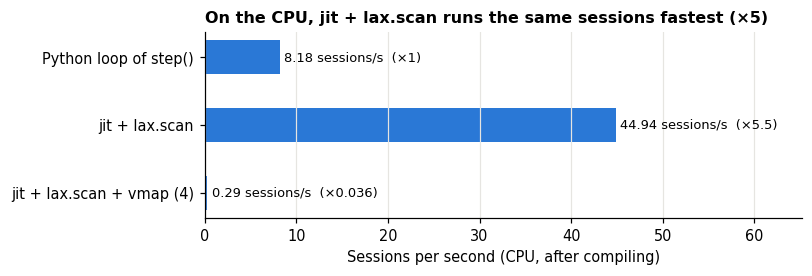

In [10]:
fig, ax = plt.subplots(figsize=(7, 2.2))
yy = np.arange(len(ways))[::-1]
ax.barh(yy, rates, color=BUY, height=0.5)
for yi, r, x in zip(yy, rates, speedups):
    ax.text(r + max(rates) * 0.01, yi, f"{r:.2f} sessions/s  (×{x:.2g})", va="center", fontsize=8.5)
ax.set_yticks(yy, ways)
ax.set_xlim(0, max(rates) * 1.45)
ax.set_xlabel(f"Sessions per second ({BACKEND}, after compiling)")
ax.grid(axis="y", visible=False)
best = ways[int(np.argmax(rates))]
ax.set_title(f"On the {BACKEND}, {best} runs the same sessions fastest (×{max(speedups):.0f})")
plt.show()

## 6. Recipe 3: three rules

**Rule 1: keep the batch shape fixed.** A compiled program is built for one input shape. A batch of a
different size compiles a new program, which for a session batch costs as much as the first compile. The
small function below shows it: it records each time JAX builds it, which happens on the first call for
each new shape.

In [11]:
builds = []


@jax.jit
def mean_cash(cash):
    builds.append(cash.shape)  # runs only while JAX builds the program, not on later calls
    return cash.mean()


for n in (4, 4, 3, 4):
    mean_cash(jnp.zeros(n))
print(f"4 calls with batch sizes 4, 4, 3, 4 built {len(builds)} programs, for shapes {builds}")

4 calls with batch sizes 4, 4, 3, 4 built 2 programs, for shapes [(4,), (3,)]


The fix is to pad a short batch up to the compiled size and drop the extra results. To pad a batch of
sessions, repeat a real session (for example the last seed key and tape index) and ignore its copies.

**Rule 2: turn on 64-bit mode for a batch.** Inside the engine, one calculation briefly works with 64-bit
integers. A single session (eager or `jax.jit`) needs nothing, but a batch must be built and called
inside `with jax.experimental.enable_x64():`, as in section 4 ([Limitations](../docs/limitations.md#numerics-and-jax)).
Without it, JAX refuses to build the batch program:

In [12]:
try:
    batched_session.lower(seed_keys, TAPES)  # no enable_x64 around it
    print("built without 64-bit mode")
except Exception as err:
    print(f"{type(err).__name__}: {str(err).splitlines()[0].rstrip(':')[:110]}")

ValueError: Cannot lower jaxpr with verifier errors


64-bit mode changes JAX's default number types inside the `with` block, so give explicit types to the
numbers you create there (`jnp.float32`, `jnp.int32`), as `threshold` does
([JAX: double precision](https://docs.jax.dev/en/latest/notebooks/Common_Gotchas_in_JAX.html#double-64bit-precision)).

**Rule 3: keep compiled programs on disk.** The setup turned on JAX's *persistent compilation cache*
([JAX: persistent compilation cache](https://docs.jax.dev/en/latest/persistent_compilation_cache.html)).
Every program compiled in this notebook was written to `.jax_cache/tutorials/`, and the next run of the
notebook loads it from there. We can see this without restarting: `jax.clear_caches()` forgets the programs
held in memory, so the next call of `compiled_session` must fetch it again, from the disk this time.

In [13]:
jax.clear_caches()  # forget the compiled programs held in memory (the files on disk stay)
t0 = time.perf_counter()
compiled_session(seed_keys[0], TAPES[0]).agent_cash.block_until_ready()
reload_s = time.perf_counter() - t0
n_files = sum(1 for p in CACHE_DIR.rglob("*") if p.is_file())
print(f"compiled session: first call {scan_first_s:.1f} s, after clearing memory {reload_s:.1f} s")
print(f"{n_files} files in the cache folder")

compiled session: first call 40.7 s, after clearing memory 2.7 s
40 files in the cache folder


The first call above shows the full compile only on the very first run of this notebook; on a later run it
too comes from the disk. The test suite and the demos use the same mechanism, with the folder `.jax_cache/`.

## 7. Recipe 4: choose the device

JAX runs on the CPU, or on an NVIDIA GPU if one is installed. Three settings:

1. **Install GPU support** with the `cuda12` extra (see the [installation guide](../README.md#4-hardware)):
   ```bash
   pip install -c constraints/verified.txt -e ".[validation,examples,cuda12]"
   ```
2. **Choose the platform** with the environment variable `JAX_PLATFORMS`, *before* JAX starts: `cpu` or
   `cuda`. The setup cell of every tutorial sets `cpu` unless you have set it already, so start Jupyter with
   ```bash
   JAX_PLATFORMS=cuda jupyter lab tutorials/
   ```
   Changing it after `import jax` has no effect: restart the kernel.
3. **Choose which GPU** with `CUDA_VISIBLE_DEVICES` (for example `CUDA_VISIBLE_DEVICES=1`); an empty value
   hides every GPU.

([JAX: installation](https://docs.jax.dev/en/latest/installation.html).) The devices JAX sees now:

In [14]:
platforms = sorted({d.platform for d in jax.devices()})
print(f"default backend: {jax.default_backend()}; devices: {len(jax.devices())} ({', '.join(platforms)})")

default backend: cpu; devices: 1 (cpu)


The cell below repeats the comparison of section 5 on a GPU, with a larger batch. It runs only when JAX
sees a GPU, and skips otherwise. The outputs saved with this notebook come from a CPU, so it shows the skip.

In [15]:
gpus = [d for d in jax.devices() if d.platform == "gpu"]
if not gpus:
    print(f"skipped: no GPU visible (JAX platforms: {', '.join(platforms)})")
else:
    n = 64  # sessions in the GPU batch; raise it to fill your GPU
    keys_n = jax.vmap(jax.random.PRNGKey)(jnp.arange(n, dtype=jnp.uint32))
    tapes_n = jnp.arange(n, dtype=jnp.int32) % session.n_tapes
    with jax.default_device(gpus[0]), jax.experimental.enable_x64():
        program = batched_session.lower(keys_n, tapes_n).compile()
        jax.block_until_ready(program(keys_n, tapes_n))  # warm-up call
        t0 = time.perf_counter()
        jax.block_until_ready(program(keys_n, tapes_n))
        gpu_batch_s = time.perf_counter() - t0
    with jax.default_device(gpus[0]):
        jax.block_until_ready(compiled_session(keys_n[0], tapes_n[0]))  # warm-up call
        t0 = time.perf_counter()
        jax.block_until_ready([compiled_session(k, t) for k, t in zip(keys_n, tapes_n)])
        gpu_loop_s = time.perf_counter() - t0
    print(f"GPU ({gpus[0].device_kind}), {n} sessions: vmap batch {n / gpu_batch_s:.1f} sessions/s, "
          f"compiled session in a loop {n / gpu_loop_s:.1f} sessions/s")

skipped: no GPU visible (JAX platforms: cpu)


## Recap

- `jax.jit` of a `jax.lax.scan` over `session.step_env` runs a whole session as one compiled program; the
  agent must decide with `jnp` operations, its "trade or not" choice as the order's `active` flag.
- `jax.vmap` of the same function runs a batch over seeds and tapes, inside `jax.experimental.enable_x64()`;
  it gives the same results, but on a CPU it is slower per session, so on a CPU call the compiled session in a
  Python loop over seeds and tapes.
- Keep the batch shape fixed (pad a short batch), turn on the persistent compilation cache before the first
  compile, and decode prices and quantities after the compiled program has finished.
- Choose the device with `JAX_PLATFORMS` before JAX starts, install the `cuda12` extra for a GPU, and
  measure your own workload on it.

## Exercises

1. **Pad a short batch.** You have three sessions but the batch program was compiled for four. Build the
   four seed keys and tape indices to call it with, and say which result to drop. *Hint:* repeat the last
   session with `jnp.concatenate`, and check that the shapes match those of `seed_keys` and `TAPES`.
2. **List the purchases.** Print every purchase of session 0 of the batch (seed 3, tape 0): its step, its
   quantity in MW and its price in EUR/MWh. *Hint:* `batch_states.agent_trades[0]` has one block of two
   rows per step; decode outside compiled code with `decode_price` and `decode_qty`.
3. **Steps per second.** Turn the sessions per second of section 5 into steps per second. *Hint:* the loop
   stops at `done`, the scan always runs `session.steps_per_episode` steps; `state.step_counter` says how
   many steps a session really took.

The solutions are in the collapsed cell at the end.

## Further reading

- [Performance](../docs/performance.md): what triggers a compile, the cache, and indicative timings for a
  real OMIE contract.
- [Sessions](../docs/sessions.md), sections *Batching* and *Choosing a tape*, and
  [Limitations](../docs/limitations.md#numerics-and-jax).
- The [installation guide](../README.md#installation), part 4 (hardware).
- The replay benchmark demo ([demos](../demos/README.md)) measures the bare engine on one real contract.
- The JAX documentation: [`jit`](https://docs.jax.dev/en/latest/jit-compilation.html),
  [`vmap`](https://docs.jax.dev/en/latest/automatic-vectorization.html),
  [`lax.scan`](https://docs.jax.dev/en/latest/_autosummary/jax.lax.scan.html), the
  [persistent compilation cache](https://docs.jax.dev/en/latest/persistent_compilation_cache.html).
- Previous: [T06 — Writing an agent](T06_writing_an_agent.ipynb).

## Solutions

In [16]:
# Solutions to the exercises (collapsed; expand to read).

# 1. Repeat the last session until the batch has the compiled size; drop the copies' results.
short_keys, short_tapes = seed_keys[:3], TAPES[:3]
pad = len(TAPES) - len(short_tapes)
padded_keys = jnp.concatenate([short_keys, jnp.repeat(short_keys[-1:], pad, axis=0)])
padded_tapes = jnp.concatenate([short_tapes, jnp.repeat(short_tapes[-1:], pad)])
print(f"1. shapes {padded_keys.shape} and {padded_tapes.shape} (compiled for {seed_keys.shape} and {TAPES.shape}); "
      f"keep results 0 to {len(short_tapes) - 1}, drop {pad}")

# 2. Rows of the trade tape: two per step (own order, resting orders); decode outside compiled code.
cfg = session.product_config
for step, rows in enumerate(np.asarray(batch_states.agent_trades[0])):
    for r in rows:
        if r[2] > 0 and r[3] == AGENT_TRADER_ID:
            print(f"2. step {step:2d}: bought {decode_qty(int(r[2]), cfg):.1f} MW at {decode_price(int(r[1]), cfg):.2f} EUR/MWh")

# 3. Steps per second = sessions per second x steps per session.
loop_steps = np.mean([int(st.step_counter) for st in loop_states])
print(f"3. Python loop: {rates[0] * loop_steps:.0f} steps/s ({loop_steps:.0f} steps per session); "
      f"compiled session: {rates[1] * session.steps_per_episode:.0f} steps/s "
      f"({session.steps_per_episode} steps per session, the last ones ignored after done)")

1. shapes (4, 2) and (4,) (compiled for (4, 2) and (4,)); keep results 0 to 2, drop 1
2. step  7: bought 1.0 MW at 49.60 EUR/MWh
2. step  9: bought 1.0 MW at 49.50 EUR/MWh
2. step 10: bought 1.0 MW at 49.50 EUR/MWh
2. step 11: bought 1.0 MW at 49.50 EUR/MWh
2. step 12: bought 1.0 MW at 49.50 EUR/MWh
3. Python loop: 491 steps/s (60 steps per session); compiled session: 2876 steps/s (64 steps per session, the last ones ignored after done)
